# Extract Embeddings: AST (Audio Spectrogram Transformer)

This notebook extracts embeddings from AST for the 600-sound dataset.

## Model Information
- **Model**: AST (Audio Spectrogram Transformer)
- **Repository**: [Official AST](https://github.com/YuanGongND/ast) | [Hugging Face](https://huggingface.co/MIT/ast-finetuned-audioset)
- **Architecture**: Vision Transformer (ViT) based
- **Layer-wise outputs**: Yes - can extract all transformer block outputs
- **Sample Rate**: 16000 Hz
- **Input**: Mel spectrogram (128 mel bins, variable time frames, typically 1024 frames = 10.24s)


## Setup and Imports

In [2]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import torch
import torchaudio
import librosa
from tqdm import tqdm

# Set paths
PROJECT_ROOT = Path("/Users/micheleesposito/Desktop/Postdoc@CNRS/Projects/Sound-DNNs-Brain-Benchmark")

# Alternative: if you start Jupyter from the project root, uncomment this:
# PROJECT_ROOT = Path.cwd()

# Verify the path exists
if not PROJECT_ROOT.exists():
    print(f"WARNING: Project root not found at {PROJECT_ROOT}")
    print("Please update PROJECT_ROOT in this cell to point to your project directory")

DATA_DIR = PROJECT_ROOT / "Data" / "stimuli"
AUDIO_DIR = DATA_DIR / "audio" / "common_unique_sets_v03_RMSnorm_Silence"
TEXT_DIR = DATA_DIR / "text"
RESULTS_DIR = PROJECT_ROOT / "results"

# AST repository path
AST_REPO = PROJECT_ROOT / "script" / "models" / "ast"
AST_SRC = AST_REPO / "src"

# Add AST to path
if AST_SRC.exists():
    sys.path.insert(0, str(AST_SRC))
    sys.path.insert(0, str(AST_REPO))

# Create results directory if it doesn't exist
RESULTS_DIR.mkdir(exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Audio directory: {AUDIO_DIR}")
print(f"Number of audio files: {len(list(AUDIO_DIR.glob('*.wav')))}")
print(f"PyTorch version: {torch.__version__}")

# Device selection: prioritize CUDA, then MPS (Apple Silicon), then CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Device: CUDA (GPU)")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"Device: MPS (Apple Silicon GPU)")
else:
    device = torch.device("cpu")
    print(f"Device: CPU")

Project root: /Users/micheleesposito/Desktop/Postdoc@CNRS/Projects/Sound-DNNs-Brain-Benchmark
Audio directory: /Users/micheleesposito/Desktop/Postdoc@CNRS/Projects/Sound-DNNs-Brain-Benchmark/Data/stimuli/audio/common_unique_sets_v03_RMSnorm_Silence
Number of audio files: 601
PyTorch version: 2.9.1
Device: MPS (Apple Silicon GPU)


## Model Setup

Load the AST model with AudioSet pretrained weights.

In [3]:
# Load AST model
try:
    from models import ASTModel
    
    # AST parameters
    # AudioSet pretrained model uses: fstride=10, tstride=10, input_tdim=1024
    # For variable length audio, we'll use a fixed input_tdim and pad/truncate
    input_tdim = 1024  # 10.24 seconds at 16kHz with 10ms hop
    input_fdim = 128   # 128 mel frequency bins
    fstride = 10
    tstride = 10
    
    print("Loading AST model (AudioSet pretrained)...")
    
    # Set TORCH_HOME for pretrained models
    pretrained_models_dir = AST_REPO / "pretrained_models"
    os.environ['TORCH_HOME'] = str(pretrained_models_dir)
    
    # Load AudioSet pretrained model
    model = ASTModel(
        label_dim=527,  # AudioSet has 527 classes
        fstride=fstride,
        tstride=tstride,
        input_fdim=input_fdim,
        input_tdim=input_tdim,
        imagenet_pretrain=True,
        audioset_pretrain=True,  # Use AudioSet pretrained weights
        model_size='base384',
        verbose=True
    )
    
    # Move model to device
    model = model.to(device)
    model.eval()
    
    print("✓ Model loaded successfully")
    print(f"Model structure:")
    print(f"  - Patch embedding: {type(model.v.patch_embed).__name__}")
    print(f"  - Number of transformer blocks: {len(model.v.blocks)}")
    print(f"  - Embedding dimension: {model.original_embedding_dim}")
    print(f"  - MLP head: {type(model.mlp_head).__name__}")
    
except ImportError as e:
    print(f"✗ Error importing AST: {e}")
    print(f"Please ensure the AST repository is at: {AST_REPO}")
    model = None
except Exception as e:
    print(f"✗ Error loading model: {e}")
    import traceback
    traceback.print_exc()
    model = None

Loading AST model (AudioSet pretrained)...
---------------AST Model Summary---------------
ImageNet pretraining: True, AudioSet pretraining: True
frequncey stride=10, time stride=10
number of patches=1212
✓ Model loaded successfully
Model structure:
  - Patch embedding: PatchEmbed
  - Number of transformer blocks: 12
  - Embedding dimension: 768
  - MLP head: Sequential


## Load and Preprocess Audio

AST expects mel spectrograms at 16kHz with 128 mel bins. We'll normalize using AudioSet statistics.

In [4]:
# Load and preprocess audio files
audio_files = sorted(list(AUDIO_DIR.glob("*.wav")))
print(f"Found {len(audio_files)} audio files")

# AST parameters
sample_rate = 16000  # AST uses 16kHz
n_mels = 128  # 128 mel frequency bins
n_fft = 512
hop_length = 160  # 10ms hop at 16kHz
target_length = 1024  # 10.24 seconds at 16kHz with 10ms hop

# AudioSet normalization statistics
norm_mean = -4.27
norm_std = 4.57

print(f"\nPreprocessing audio files...")
print(f"  Target sample rate: {sample_rate} Hz")
print(f"  Mel bins: {n_mels}")
print(f"  Target length: {target_length} frames (10.24s)")

preprocessed_spectrograms = []

for audio_file in tqdm(audio_files, desc="Loading audio"):
    try:
        # Load audio with librosa (more robust on macOS)
        waveform, sr = librosa.load(str(audio_file), sr=sample_rate, mono=True)
        
        # Convert to mel spectrogram
        mel_spec = librosa.feature.melspectrogram(
            y=waveform,
            sr=sample_rate,
            n_fft=n_fft,
            hop_length=hop_length,
            n_mels=n_mels,
            fmin=0,
            fmax=sample_rate // 2
        )
        
        # Convert to log scale (dB)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Transpose to (time, freq) format expected by AST
        mel_spec_db = mel_spec_db.T  # Shape: (time_frames, n_mels)
        
        # Pad or truncate to target_length
        if mel_spec_db.shape[0] < target_length:
            # Pad with zeros
            pad_length = target_length - mel_spec_db.shape[0]
            mel_spec_db = np.pad(mel_spec_db, ((0, pad_length), (0, 0)), mode='constant', constant_values=0)
        elif mel_spec_db.shape[0] > target_length:
            # Truncate
            mel_spec_db = mel_spec_db[:target_length, :]
        
        # Normalize using AudioSet statistics
        mel_spec_db = (mel_spec_db - norm_mean) / (norm_std * 2)
        
        # Convert to tensor
        mel_spec_tensor = torch.from_numpy(mel_spec_db).float()
        
        preprocessed_spectrograms.append(mel_spec_tensor)
        
    except Exception as e:
        print(f"✗ Error loading {audio_file.name}: {e}")
        continue

print(f"✓ Preprocessed {len(preprocessed_spectrograms)} audio files")
if len(preprocessed_spectrograms) > 0:
    print(f"  Spectrogram shape: {preprocessed_spectrograms[0].shape}")

Found 601 audio files

Preprocessing audio files...
  Target sample rate: 16000 Hz
  Mel bins: 128
  Target length: 1024 frames (10.24s)


Loading audio: 100%|██████████| 601/601 [00:01<00:00, 303.76it/s]

✓ Preprocessed 601 audio files
  Spectrogram shape: torch.Size([1024, 128])


In [5]:
# SELECTIVE EXTRACTION: Extract only key layers (max 55 layers)
if model is None:
    print("✗ Model not loaded. Please fix the model loading step above.")
else:
    print("="*70)
    print("SELECTIVE EXTRACTION: AST (target: ≤55 layers)")
    print("="*70)
    
    def is_excluded_layer(module):
        """Check if a module should be excluded from extraction."""
        module_type = type(module).__name__
        if 'BatchNorm' in module_type or 'Dropout' in module_type:
            return True
        # Note: LayerNorm is important in transformers, so we keep it
        return False
    
    # Define selected layers based on AST architecture (Vision Transformer)
    selected_layers = []
    
    # 1. Patch embedding
    selected_layers.append(('patch_embed', model.v.patch_embed))
    
    # 2. Transformer blocks (select key blocks: first, middle, last, and a few in between)
    n_blocks = len(model.v.blocks)
    print(f"\nTotal transformer blocks: {n_blocks}")
    
    # Select blocks: first, last, and evenly spaced middle blocks
    if n_blocks <= 12:
        # For 12 blocks: select 0, 2, 4, 6, 8, 10, 11 (7 blocks)
        selected_block_indices = [0, 2, 4, 6, 8, 10, 11] if n_blocks == 12 else list(range(n_blocks))
    else:
        # For more blocks, select evenly spaced
        selected_block_indices = [0] + list(range(2, n_blocks-1, max(1, (n_blocks-3)//5))) + [n_blocks-1]
    
    for block_idx in selected_block_indices:
        if block_idx < n_blocks:
            block = model.v.blocks[block_idx]
            selected_layers.append((f'block{block_idx}', block))
            
            # Also extract attention and MLP from selected blocks
            if hasattr(block, 'attn') and not is_excluded_layer(block.attn):
                selected_layers.append((f'block{block_idx}.attn', block.attn))
            if hasattr(block, 'mlp') and not is_excluded_layer(block.mlp):
                selected_layers.append((f'block{block_idx}.mlp', block.mlp))
    
    # 3. Final norm
    if hasattr(model.v, 'norm'):
        selected_layers.append(('norm', model.v.norm))
    
    # 4. MLP head
    if hasattr(model, 'mlp_head'):
        selected_layers.append(('mlp_head', model.mlp_head))
    
    print(f"\n✓ Selected {len(selected_layers)} key layers for extraction")
    print(f"  Layer list:")
    for layer_name, _ in selected_layers:
        print(f"    - {layer_name}")
    
    # Set up hooks
    layer_activations = {}
    final_embeddings = []
    
    def get_hook(layer_name):
        def hook(module, input, output):
            if isinstance(output, torch.Tensor):
                layer_activations[layer_name] = output.detach()
            elif isinstance(output, (tuple, list)):
                layer_activations[layer_name] = tuple(
                    o.detach() if isinstance(o, torch.Tensor) else o 
                    for o in output
                )
            else:
                layer_activations[layer_name] = output
        return hook
    
    hooks = []
    for layer_name, module in selected_layers:
        if not is_excluded_layer(module):
            hooks.append(module.register_forward_hook(get_hook(layer_name)))
    
    print(f"\nRegistered {len(hooks)} hooks")
    print(f"\nProcessing {len(preprocessed_spectrograms)} audio files...")
    
    # Initialize layer storage
    all_layer_embeddings = {}
    
    with torch.no_grad():
        for audio_idx, mel_spec in enumerate(tqdm(preprocessed_spectrograms, desc="Extracting embeddings")):
            mel_spec = mel_spec.to(device)
            layer_activations.clear()
            
            # Forward pass (AST expects: batch, time, freq)
            mel_spec_batch = mel_spec.unsqueeze(0)  # Add batch dimension
            audio_features = model(mel_spec_batch)
            
            # Get final embedding (before mlp_head classification)
            # The final embedding is the average of cls and dist tokens after norm
            if 'norm' in layer_activations:
                norm_output = layer_activations['norm']
                if isinstance(norm_output, torch.Tensor):
                    # Average cls and dist tokens: (norm_output[:, 0] + norm_output[:, 1]) / 2
                    embedding = (norm_output[:, 0] + norm_output[:, 1]) / 2
                    final_embeddings.append(embedding.cpu().numpy())
            elif isinstance(audio_features, torch.Tensor):
                # Fallback: use model output (after mlp_head)
                final_embeddings.append(audio_features.cpu().numpy())
            
            # Store layer activations and print shapes (first audio file only)
            if audio_idx == 0:
                print(f"\n  Layer shapes (first audio file):")
            
            for layer_name, activation in layer_activations.items():
                if layer_name not in all_layer_embeddings:
                    all_layer_embeddings[layer_name] = []
                
                if isinstance(activation, torch.Tensor):
                    act_np = activation.cpu().numpy()
                    
                    # Print layer name and shape (first audio file only)
                    if audio_idx == 0:
                        print(f"    - {layer_name}: {act_np.shape}")
                    
                    # Process and pool
                    # For transformer outputs: shape is (batch, seq_len, hidden_dim)
                    if len(act_np.shape) == 3:  # [B, N, D] - transformer sequence
                        # Global average pooling over sequence dimension
                        pooled = act_np.mean(axis=1)  # [B, D]
                        all_layer_embeddings[layer_name].append({
                            'full': act_np,
                            'pooled': pooled
                        })
                    elif len(act_np.shape) == 4:  # [B, C, H, W] - conv outputs
                        pooled = act_np.mean(axis=(2, 3))
                        all_layer_embeddings[layer_name].append({
                            'full': act_np,
                            'pooled': pooled
                        })
                    elif len(act_np.shape) == 2:  # [B, D]
                        all_layer_embeddings[layer_name].append({
                            'full': act_np,
                            'pooled': act_np
                        })
                    else:
                        pooled = act_np.mean(axis=tuple(range(1, len(act_np.shape))))
                        all_layer_embeddings[layer_name].append({
                            'full': act_np,
                            'pooled': pooled
                        })
                elif isinstance(activation, (tuple, list)):
                    processed = []
                    for a in activation:
                        if isinstance(a, torch.Tensor):
                            a_np = a.cpu().numpy()
                            if len(a_np.shape) >= 3:
                                processed.append(a_np.mean(axis=tuple(range(2, len(a_np.shape)))))
                            else:
                                processed.append(a_np)
                        else:
                            processed.append(a)
                    all_layer_embeddings[layer_name].append({
                        'full': [a.cpu().numpy() if isinstance(a, torch.Tensor) else a for a in activation],
                        'pooled': processed
                    })
                else:
                    all_layer_embeddings[layer_name].append({
                        'full': activation,
                        'pooled': activation
                    })
    
    # Convert to numpy arrays
    if len(final_embeddings) > 0:
        final_embeddings = np.array(final_embeddings)
        if len(final_embeddings.shape) == 3:
            if final_embeddings.shape[1] == 1:
                final_embeddings = final_embeddings.squeeze(1)
            else:
                final_embeddings = final_embeddings[:, 0, :]
    else:
        final_embeddings = np.array([])
    
    # Convert layer embeddings to arrays (HIGHLY OPTIMIZED: batch processing)
    print(f"\nConverting layer embeddings to arrays (optimized)...")
    layer_embeddings_dict = {}
    layer_embeddings_pooled_dict = {}
    
    # Process all layers efficiently
    for layer_name, embeddings_list in tqdm(all_layer_embeddings.items(), desc="Converting layer embeddings"):
        n_items = len(embeddings_list)
        if n_items == 0:
            continue
        
        # Fast extraction: single pass, pre-allocate lists
        pooled_list = [None] * n_items
        full_list = [None] * n_items
        pooled_count = 0
        full_count = 0
        
        for i, emb in enumerate(embeddings_list):
            if isinstance(emb, dict):
                if 'pooled' in emb:
                    pooled_list[pooled_count] = emb['pooled']
                    pooled_count += 1
                if 'full' in emb:
                    full_list[full_count] = emb['full']
                    full_count += 1
        
        # Trim lists to actual size
        if pooled_count > 0:
            pooled_list = pooled_list[:pooled_count]
            # Fast path: if first item is numpy array, try direct stack
            if isinstance(pooled_list[0], np.ndarray):
                first_shape = pooled_list[0].shape
                first_dtype = pooled_list[0].dtype
                # Quick check: only verify first few items have same shape (faster than all())
                if all(isinstance(x, np.ndarray) and x.shape == first_shape and x.dtype == first_dtype 
                       for x in pooled_list[:min(10, len(pooled_list))]):
                    try:
                        layer_embeddings_pooled_dict[layer_name] = np.stack(pooled_list, axis=0)
                    except (ValueError, TypeError):
                        # Shapes don't match, use object array
                        layer_embeddings_pooled_dict[layer_name] = np.array(pooled_list, dtype=object)
                else:
                    layer_embeddings_pooled_dict[layer_name] = np.array(pooled_list, dtype=object)
            else:
                layer_embeddings_pooled_dict[layer_name] = np.array(pooled_list, dtype=object)
        
        if full_count > 0:
            full_list = full_list[:full_count]
            # Fast path: if first item is numpy array, try direct stack
            if isinstance(full_list[0], np.ndarray):
                first_shape = full_list[0].shape
                first_dtype = full_list[0].dtype
                # Quick check: only verify first few items have same shape (faster than all())
                if all(isinstance(x, np.ndarray) and x.shape == first_shape and x.dtype == first_dtype 
                       for x in full_list[:min(10, len(full_list))]):
                    try:
                        layer_embeddings_dict[layer_name] = np.stack(full_list, axis=0)
                    except (ValueError, TypeError):
                        # Shapes don't match, use object array
                        layer_embeddings_dict[layer_name] = np.array(full_list, dtype=object)
                else:
                    layer_embeddings_dict[layer_name] = np.array(full_list, dtype=object)
            else:
                layer_embeddings_dict[layer_name] = np.array(full_list, dtype=object)
    
    print(f"✓ Converted {len(layer_embeddings_pooled_dict)} layers to arrays")
    
    # Remove hooks
    for hook in hooks:
        hook.remove()
    
    # Store results
    all_results = {
        'AST': {
            'final_embeddings': final_embeddings,
            'layer_embeddings': layer_embeddings_pooled_dict,
            'layer_embeddings_full': layer_embeddings_dict,
            'checkpoint_name': 'AST-AudioSet-pretrained'
        }
    }
    
    print(f"\n{'='*70}")
    print(f"✓ Extraction complete!")
    if len(final_embeddings) > 0:
        print(f"  Final embeddings shape: {final_embeddings.shape}")
    print(f"  Layer embeddings extracted: {len(layer_embeddings_pooled_dict)} layers")
    print(f"\n  Final layer breakdown:")
    for layer_name in sorted(layer_embeddings_pooled_dict.keys()):
        emb = layer_embeddings_pooled_dict[layer_name]
        if isinstance(emb, np.ndarray):
            print(f"    - {layer_name}: {emb.shape}")
        else:
            print(f"    - {layer_name}: list with {len(emb)} items")
    print(f"{'='*70}")


SELECTIVE EXTRACTION: AST (target: ≤55 layers)

Total transformer blocks: 12

✓ Selected 24 key layers for extraction
  Layer list:
    - patch_embed
    - block0
    - block0.attn
    - block0.mlp
    - block2
    - block2.attn
    - block2.mlp
    - block4
    - block4.attn
    - block4.mlp
    - block6
    - block6.attn
    - block6.mlp
    - block8
    - block8.attn
    - block8.mlp
    - block10
    - block10.attn
    - block10.mlp
    - block11
    - block11.attn
    - block11.mlp
    - norm
    - mlp_head

Registered 24 hooks

Processing 601 audio files...


Extracting embeddings:   1%|          | 4/601 [00:00<00:57, 10.36it/s]


  Layer shapes (first audio file):
    - patch_embed: (1, 1212, 768)
    - block0.attn: (1, 1214, 768)
    - block0.mlp: (1, 1214, 768)
    - block0: (1, 1214, 768)
    - block2.attn: (1, 1214, 768)
    - block2.mlp: (1, 1214, 768)
    - block2: (1, 1214, 768)
    - block4.attn: (1, 1214, 768)
    - block4.mlp: (1, 1214, 768)
    - block4: (1, 1214, 768)
    - block6.attn: (1, 1214, 768)
    - block6.mlp: (1, 1214, 768)
    - block6: (1, 1214, 768)
    - block8.attn: (1, 1214, 768)
    - block8.mlp: (1, 1214, 768)
    - block8: (1, 1214, 768)
    - block10.attn: (1, 1214, 768)
    - block10.mlp: (1, 1214, 768)
    - block10: (1, 1214, 768)
    - block11.attn: (1, 1214, 768)
    - block11.mlp: (1, 1214, 768)
    - block11: (1, 1214, 768)
    - norm: (1, 1214, 768)
    - mlp_head: (1, 527)


Extracting embeddings: 100%|██████████| 601/601 [00:31<00:00, 18.94it/s]



Converting layer embeddings to arrays (optimized)...


Converting layer embeddings: 100%|██████████| 24/24 [02:37<00:00,  6.58s/it]

✓ Converted 24 layers to arrays

✓ Extraction complete!
  Final embeddings shape: (601, 768)
  Layer embeddings extracted: 24 layers

  Final layer breakdown:
    - block0: (601, 1, 768)
    - block0.attn: (601, 1, 768)
    - block0.mlp: (601, 1, 768)
    - block10: (601, 1, 768)
    - block10.attn: (601, 1, 768)
    - block10.mlp: (601, 1, 768)
    - block11: (601, 1, 768)
    - block11.attn: (601, 1, 768)
    - block11.mlp: (601, 1, 768)
    - block2: (601, 1, 768)
    - block2.attn: (601, 1, 768)
    - block2.mlp: (601, 1, 768)
    - block4: (601, 1, 768)
    - block4.attn: (601, 1, 768)
    - block4.mlp: (601, 1, 768)
    - block6: (601, 1, 768)
    - block6.attn: (601, 1, 768)
    - block6.mlp: (601, 1, 768)
    - block8: (601, 1, 768)
    - block8.attn: (601, 1, 768)
    - block8.mlp: (601, 1, 768)
    - mlp_head: (601, 1, 527)
    - norm: (601, 1, 768)
    - patch_embed: (601, 1, 768)


## Create all_layer_activations Structure

Convert extraction results into format expected by visualization/analysis cells.


In [6]:
# Create all_layer_activations structure for visualization/analysis cells
if 'all_results' in globals() and 'AST' in all_results and 'all_layer_embeddings' in globals():
    print("="*70)
    print("Creating all_layer_activations structure for analysis...")
    print("="*70)
    
    results = all_results['AST']
    
    # Reconstruct all_layer_activations from all_layer_embeddings
    all_audio_activations = []
    layer_names_set = set()
    
    # Get number of audio files
    n_files = len(preprocessed_spectrograms)
    
    # Reconstruct per-file structure from all_layer_embeddings
    for audio_idx in range(n_files):
        audio_layer_dict = {}
        
        # Add layer activations from all_layer_embeddings
        for layer_name, embeddings_list in all_layer_embeddings.items():
            layer_names_set.add(layer_name)
            
            if audio_idx < len(embeddings_list):
                # Each item in embeddings_list is a dict with 'full' and 'pooled'
                audio_layer_dict[layer_name] = embeddings_list[audio_idx]
        
        all_audio_activations.append(audio_layer_dict)
    
    # Also add final embedding if available
    if 'final_embeddings' in results and len(results['final_embeddings']) > 0:
        final_embeddings = results['final_embeddings']
        for audio_idx in range(min(len(final_embeddings), len(all_audio_activations))):
            final_emb = final_embeddings[audio_idx]
            all_audio_activations[audio_idx]['final_embedding'] = {
                'full': final_emb,
                'pooled': final_emb
            }
            layer_names_set.add('final_embedding')
    
    # Create all_layer_activations structure
    all_layer_activations = {
        'AST': {
            'layer_names': sorted(list(layer_names_set)),
            'layer_activations': all_audio_activations,
            'checkpoint_name': 'AST-AudioSet-pretrained'
        }
    }
    
    print(f"✓ Created all_layer_activations structure")
    print(f"  - {len(layer_names_set)} layers")
    print(f"  - {len(all_audio_activations)} audio files")
    layer_list = sorted(list(layer_names_set))
    if len(layer_list) > 10:
        print(f"  - Layer names (first 10): {layer_list[:10]}...")
    else:
        print(f"  - Layer names: {layer_list}")
    print(f"\n{'='*70}")
    print("✓ Ready for visualization and analysis!")
    print(f"{'='*70}")
else:
    print("✗ all_results or all_layer_embeddings not found.")
    print("  Please run the selective extraction cell first.")


Creating all_layer_activations structure for analysis...
✓ Created all_layer_activations structure
  - 25 layers
  - 601 audio files
  - Layer names (first 10): ['block0', 'block0.attn', 'block0.mlp', 'block10', 'block10.attn', 'block10.mlp', 'block11', 'block11.attn', 'block11.mlp', 'block2']...

✓ Ready for visualization and analysis!


## Save Embeddings

Save final embeddings and layer-wise activations to organized directory structure.


In [7]:
# Set up organized folder structure
AST_RESULTS_DIR = RESULTS_DIR / "AST"
embeddings_dir = AST_RESULTS_DIR / "embeddings"
figures_dir = AST_RESULTS_DIR / "figures"
summaries_dir = AST_RESULTS_DIR

# Create directories
embeddings_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
summaries_dir.mkdir(parents=True, exist_ok=True)

model_name = "AST"

if 'all_results' in globals() and 'AST' in all_results:
    results = all_results['AST']
    final_embeddings = results['final_embeddings']
    
    if final_embeddings is not None and len(final_embeddings) > 0:
        print(f"\nSaving embeddings to {embeddings_dir}...")
        
        # Save final embeddings
        embeddings_path = embeddings_dir / f"{model_name}_embeddings.npy"
        np.save(embeddings_path, final_embeddings)
        print(f"  ✓ Final embeddings: {final_embeddings.shape}")
        
        # Save layer-wise embeddings (pooled versions)
        if 'layer_embeddings' in results and results['layer_embeddings']:
            layer_embeddings_dir = embeddings_dir / f"{model_name}_layers"
            layer_embeddings_dir.mkdir(exist_ok=True)
            
            for layer_name, emb_array in results['layer_embeddings'].items():
                if isinstance(emb_array, np.ndarray):
                    layer_path = layer_embeddings_dir / f"{layer_name}_embeddings.npy"
                    np.save(layer_path, emb_array)
                else:
                    # Save as pickle if it's a list
                    import pickle
                    layer_path = layer_embeddings_dir / f"{layer_name}_embeddings.pkl"
                    with open(layer_path, 'wb') as f:
                        pickle.dump(emb_array, f)
            
            print(f"  ✓ Layer embeddings: {len(results['layer_embeddings'])} layers")
        
        # Save metadata
        metadata = pd.DataFrame({
            "file_name": [f.name for f in audio_files],
            "file_path": [str(f) for f in audio_files],
            "index": range(len(audio_files))
        })
        metadata_path = embeddings_dir / f"{model_name}_metadata.csv"
        metadata.to_csv(metadata_path, index=False)
        
        # Save summary
        summary = {
            "model_name": model_name,
            "n_files": len(audio_files),
            "embedding_dim": final_embeddings.shape[1] if len(final_embeddings.shape) > 1 else 1,
            "embeddings_shape": final_embeddings.shape,
            "layers_extracted": list(results['layer_embeddings'].keys()) if 'layer_embeddings' in results else [],
            "sample_rate": sample_rate,
            "n_transformer_blocks": len(model.v.blocks) if model is not None else 0
        }
        summary_path = summaries_dir / f"{model_name}_summary.txt"
        with open(summary_path, "w") as f:
            for key, value in summary.items():
                f.write(f"{key}: {value}\n")
        
        print(f"\n{'='*70}")
        print(f"✓ All embeddings saved successfully!")
        print(f"  Location: {embeddings_dir}")
        print(f"{'='*70}")
        
else:
    print("✗ No embeddings to save. Please run the extraction cell first.")



Saving embeddings to /Users/micheleesposito/Desktop/Postdoc@CNRS/Projects/Sound-DNNs-Brain-Benchmark/results/AST/embeddings...
  ✓ Final embeddings: (601, 768)
  ✓ Layer embeddings: 24 layers

✓ All embeddings saved successfully!
  Location: /Users/micheleesposito/Desktop/Postdoc@CNRS/Projects/Sound-DNNs-Brain-Benchmark/results/AST/embeddings


## Quality Check and Visualization

Verify that embeddings were extracted correctly, check for NaNs, and visualize embeddings using t-SNE.


In [ ]:
# Quality check and verification
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import seaborn as sns

# Ensure directory variables are defined
if 'AST_RESULTS_DIR' not in globals():
    AST_RESULTS_DIR = RESULTS_DIR / "AST"
    embeddings_dir = AST_RESULTS_DIR / "embeddings"
    figures_dir = AST_RESULTS_DIR / "figures"
    summaries_dir = AST_RESULTS_DIR
    embeddings_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    summaries_dir.mkdir(parents=True, exist_ok=True)

print("="*70)
print("QUALITY CHECK: Verifying extracted embeddings")
print("="*70)

# Check final embeddings
if 'all_results' in globals() and 'AST' in all_results:
    results = all_results['AST']
    embeddings = results['final_embeddings']
    
    # Check for NaNs
    nan_count = np.isnan(embeddings).sum()
    inf_count = np.isinf(embeddings).sum()
    
    # Check shape
    expected_shape = (len(audio_files), embeddings.shape[1] if len(embeddings.shape) > 1 else 1)
    shape_ok = embeddings.shape == expected_shape
    
    # Basic statistics
    mean_val = np.nanmean(embeddings)
    std_val = np.nanstd(embeddings)
    min_val = np.nanmin(embeddings)
    max_val = np.nanmax(embeddings)
    
    status = "✓" if (nan_count == 0 and inf_count == 0 and shape_ok) else "✗"
    
    print(f"\n{status} AST:")
    print(f"    Shape: {embeddings.shape} (expected: {expected_shape})")
    print(f"    NaNs: {nan_count}, Infs: {inf_count}")
    print(f"    Stats: mean={mean_val:.4f}, std={std_val:.4f}, range=[{min_val:.4f}, {max_val:.4f}]")
    
    if nan_count > 0 or inf_count > 0 or not shape_ok:
        print(f"\n⚠ WARNING: Found issues in embeddings!")
    else:
        print(f"\n✓ Final embeddings passed quality checks!")
    
    # Check layer activations if available
    if 'all_layer_activations' in globals() and 'AST' in all_layer_activations:
        activations_data = all_layer_activations['AST']
        layer_names = activations_data['layer_names']
        all_audio_activations = activations_data['layer_activations']
        
        print(f"\n2. Checking layer activations...")
        print(f"  AST: {len(layer_names)} layers, {len(all_audio_activations)} audio files")
        
        # Check a few sample layers
        sample_layers = layer_names[:min(10, len(layer_names))]  # Check first 10 layers
        
        for layer_name in sample_layers:
            layer_acts = []
            for audio_act in all_audio_activations[:10]:  # Check first 10 files
                if layer_name in audio_act and 'pooled' in audio_act[layer_name]:
                    act = audio_act[layer_name]['pooled']
                    if isinstance(act, np.ndarray):
                        layer_acts.append(act)
            
            if layer_acts:
                layer_array = np.array(layer_acts)
                nan_count = np.isnan(layer_array).sum()
                inf_count = np.isinf(layer_array).sum()
                status = "✓" if (nan_count == 0 and inf_count == 0) else "✗"
                print(f"    {status} {layer_name}: shape={layer_array.shape}, NaNs={nan_count}, Infs={inf_count}")

print(f"\n{'='*70}")


QUALITY CHECK: Verifying extracted embeddings

✓ AST:
    Shape: (601, 768) (expected: (601, 768))
    NaNs: 0, Infs: 0
    Stats: mean=0.0265, std=1.1792, range=[-8.8901, 5.9225]

✓ Final embeddings passed quality checks!

2. Checking layer activations...
  AST: 25 layers, 601 audio files
    ✓ block0: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block0.attn: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block0.mlp: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block10: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block10.attn: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block10.mlp: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block11: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block11.attn: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block11.mlp: shape=(10, 1, 768), NaNs=0, Infs=0
    ✓ block2: shape=(10, 1, 768), NaNs=0, Infs=0



### Visualize Embeddings with t-SNE

Visualize embeddings from different layers to see how representations evolve through the network.


Visualizing 6 layers: ['patch_embed', 'block0', 'block2', 'block8', 'norm', 'final_embedding']
  patch_embed: PCA explained variance: 99.95%
  Computing t-SNE for layer: patch_embed...


TypeError: TSNE.__init__() got an unexpected keyword argument 'n_iter'

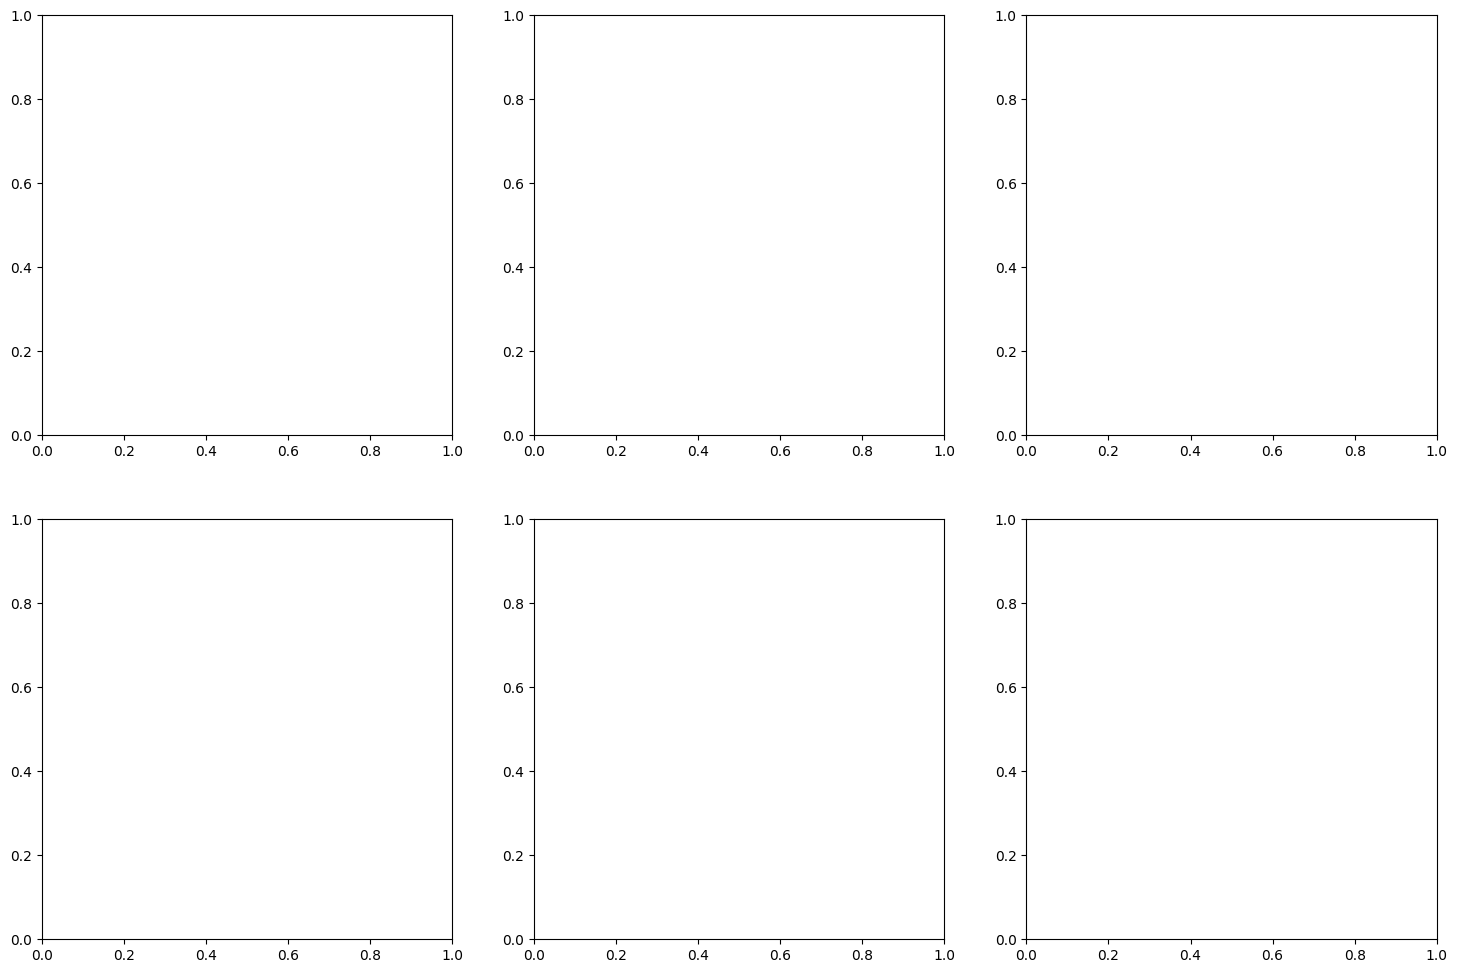

In [ ]:
# t-SNE Visualization for different layers
if 'all_layer_activations' in globals() and 'AST' in all_layer_activations:
    activations_data = all_layer_activations['AST']
    layer_names = activations_data['layer_names']
    all_audio_activations = activations_data['layer_activations']
    
    # Select representative layers to visualize
    selected_layers = []
    
    # Add patch_embed
    if 'patch_embed' in layer_names:
        selected_layers.append('patch_embed')
    
    # Add selected transformer blocks
    block_layers = [l for l in layer_names if l.startswith('block') and '.' not in l]
    if len(block_layers) > 0:
        # Select first, middle, last blocks
        selected_blocks = [block_layers[0]]
        if len(block_layers) > 1:
            selected_blocks.append(block_layers[len(block_layers)//2])
        if len(block_layers) > 2:
            selected_blocks.append(block_layers[-1])
        selected_layers.extend(selected_blocks)
    
    # Add norm and final_embedding
    if 'norm' in layer_names:
        selected_layers.append('norm')
    if 'final_embedding' in [k for d in all_audio_activations for k in d.keys()]:
        selected_layers.append('final_embedding')
    
    selected_layers = selected_layers[:6]  # Max 6 layers for visualization
    
    print(f"Visualizing {len(selected_layers)} layers: {selected_layers}")
    
    # Create subplots
    n_cols = 3
    n_rows = (len(selected_layers) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6*n_rows))
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    axes = axes.flatten()
    
    for idx, layer_name in enumerate(selected_layers):
        # Collect pooled activations for this layer
        layer_acts = []
        for audio_act in all_audio_activations:
            if layer_name in audio_act and 'pooled' in audio_act[layer_name]:
                act = audio_act[layer_name]['pooled']
                if isinstance(act, np.ndarray):
                    layer_acts.append(act.flatten())
                elif isinstance(act, (list, tuple)):
                    layer_acts.append(np.array(act).flatten())
        
        if layer_acts:
            layer_array = np.array(layer_acts)
            
            # Remove NaNs/Infs
            valid_mask = ~(np.isnan(layer_array).any(axis=1) | np.isinf(layer_array).any(axis=1))
            layer_array_clean = layer_array[valid_mask]
            
            if layer_array_clean.shape[0] > 0 and layer_array_clean.shape[1] > 1:
                # PCA if needed
                if layer_array_clean.shape[1] > 50:
                    pca = PCA(n_components=50, random_state=42)
                    layer_pca = pca.fit_transform(layer_array_clean)
                    print(f"  {layer_name}: PCA explained variance: {pca.explained_variance_ratio_.sum():.2%}")
                else:
                    layer_pca = layer_array_clean
                
                # t-SNE
                print(f"  Computing t-SNE for layer: {layer_name}...")
                tsne = TSNE(n_components=2, random_state=42, perplexity=30,verbose=0)
                layer_tsne = tsne.fit_transform(layer_pca)
                
                # Plot
                axes[idx].scatter(layer_tsne[:, 0], layer_tsne[:, 1], alpha=0.6, s=20)
                axes[idx].set_title(f'{layer_name}\n({layer_array_clean.shape[1]}D → 2D)')
                axes[idx].set_xlabel('t-SNE Dim 1')
                axes[idx].set_ylabel('t-SNE Dim 2')
                axes[idx].grid(True, alpha=0.3)
            else:
                axes[idx].text(0.5, 0.5, f'{layer_name}\nNo valid data', 
                              ha='center', va='center', transform=axes[idx].transAxes)
                axes[idx].set_title(layer_name)
        else:
            axes[idx].text(0.5, 0.5, f'{layer_name}\nNo data', 
                          ha='center', va='center', transform=axes[idx].transAxes)
            axes[idx].set_title(layer_name)
    
    # Hide unused subplots
    for idx in range(len(selected_layers), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Layer-wise t-SNE: AST', fontsize=14, y=0.995)
    plt.tight_layout()
    
    # Save figure
    fig_path = figures_dir / "AST_layers_tsne.png"
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    print(f"  ✓ Saved layer-wise t-SNE plot to {fig_path}")
    plt.show()
    
else:
    print("Layer activations not available. Run the extraction cells first.")


### Embedding Statistics and Layer Breakdown

Generate summary statistics and layer breakdown visualization.


In [ ]:
# Create summary statistics and layer breakdown
if 'all_results' in globals() and 'AST' in all_results:
    results = all_results['AST']
    embeddings = results['final_embeddings']
    
    # Remove NaNs/Infs for statistics
    valid_mask = ~(np.isnan(embeddings).any(axis=1) | np.isinf(embeddings).any(axis=1))
    embeddings_clean = embeddings[valid_mask]
    
    summary_data = {
        'Model': 'AST',
        'Embedding Dim': embeddings.shape[1] if len(embeddings.shape) > 1 else 1,
        'N Samples': embeddings.shape[0],
        'Valid Samples': embeddings_clean.shape[0],
        'Has NaNs': np.isnan(embeddings).any(),
        'Has Infs': np.isinf(embeddings).any(),
        'Mean': np.nanmean(embeddings),
        'Std': np.nanstd(embeddings),
        'Min': np.nanmin(embeddings),
        'Max': np.nanmax(embeddings)
    }
    
    # Add layer count information
    if 'all_layer_activations' in globals() and 'AST' in all_layer_activations:
        n_layers = len(all_layer_activations['AST']['layer_names'])
        summary_data['N Layers'] = n_layers
    else:
        summary_data['N Layers'] = len(results.get('layer_embeddings', {}))
    
    summary_df = pd.DataFrame([summary_data])
    
    print("\nSummary Statistics for AST:")
    print("="*100)
    print(summary_df.to_string(index=False))
    print("="*100)
    
    # Save summary
    summary_path = summaries_dir / "embedding_quality_summary.csv"
    summary_df.to_csv(summary_path, index=False)
    print(f"\n✓ Saved summary to {summary_path}")
    
    # Layer breakdown visualization if available
    if 'all_layer_activations' in globals() and 'AST' in all_layer_activations:
        activations_data = all_layer_activations['AST']
        layer_names = activations_data['layer_names']
        
        # Count layers by type
        layer_types = {}
        for layer_name in layer_names:
            if 'patch_embed' in layer_name:
                layer_type = 'Patch Embedding'
            elif 'block' in layer_name:
                if 'attn' in layer_name:
                    layer_type = 'Attention'
                elif 'mlp' in layer_name:
                    layer_type = 'MLP'
                else:
                    layer_type = 'Transformer Block'
            elif 'norm' in layer_name:
                layer_type = 'Layer Norm'
            elif 'mlp_head' in layer_name:
                layer_type = 'MLP Head'
            elif 'final_embedding' in layer_name:
                layer_type = 'Final Embedding'
            else:
                layer_type = 'Other'
            
            layer_types[layer_type] = layer_types.get(layer_type, 0) + 1
        
        # Create bar plot
        fig2, ax2 = plt.subplots(1, 1, figsize=(10, 6))
        types = list(layer_types.keys())
        counts = list(layer_types.values())
        
        bars = ax2.barh(types, counts, color='steelblue', edgecolor='black', linewidth=0.5)
        ax2.set_xlabel('Number of Layers', fontsize=12)
        ax2.set_title('AST Layer Breakdown by Type', fontsize=14, fontweight='bold')
        ax2.grid(True, alpha=0.3, axis='x')
        
        # Add value labels
        for bar, count in zip(bars, counts):
            width = bar.get_width()
            ax2.text(width, bar.get_y() + bar.get_height()/2, 
                   f' {int(count)}', ha='left', va='center', fontsize=10, fontweight='bold')
        
        plt.tight_layout()
        
        # Save figure
        fig_path2 = figures_dir / "AST_layer_breakdown.png"
        plt.savefig(fig_path2, dpi=150, bbox_inches='tight')
        print(f"✓ Saved layer breakdown plot to {fig_path2}")
        plt.show()
        
        print(f"\nLayer breakdown:")
        for layer_type, count in sorted(layer_types.items(), key=lambda x: x[1], reverse=True):
            print(f"  {layer_type}: {count} layers")
        
        # Layer correlation analysis
        print(f"\n{'='*70}")
        print("Computing inter-layer correlations...")
        print(f"{'='*70}")
        
        # Get main transformer block outputs
        block_layers = [l for l in layer_names if l.startswith('block') and '.' not in l]
        block_layers = sorted(block_layers, key=lambda x: int(x.replace('block', '')))
        
        # Also include patch_embed, norm, and final_embedding if available
        selected_layers = []
        if 'patch_embed' in layer_names:
            selected_layers.append('patch_embed')
        selected_layers.extend(block_layers[:min(8, len(block_layers))])  # Max 8 blocks
        if 'norm' in layer_names:
            selected_layers.append('norm')
        if 'final_embedding' in [k for d in activations_data['layer_activations'] for k in d.keys()]:
            selected_layers.append('final_embedding')
        
        # Extract pooled activations for selected layers
        layer_activations_dict = {}
        for layer_name in selected_layers:
            layer_acts = []
            for audio_act in activations_data['layer_activations']:
                if layer_name in audio_act and 'pooled' in audio_act[layer_name]:
                    act = audio_act[layer_name]['pooled']
                    if isinstance(act, np.ndarray):
                        layer_acts.append(act.flatten())
                    elif isinstance(act, (list, tuple)):
                        layer_acts.append(np.array(act).flatten())
            
            if layer_acts:
                try:
                    layer_array = np.array(layer_acts)
                    # Remove NaNs/Infs
                    valid_mask = ~(np.isnan(layer_array).any(axis=1) | np.isinf(layer_array).any(axis=1))
                    layer_array_clean = layer_array[valid_mask]
                    
                    if layer_array_clean.shape[0] > 0:
                        layer_activations_dict[layer_name] = layer_array_clean
                except:
                    pass
        
        if len(layer_activations_dict) > 1:
            # Compute correlation matrix
            from scipy.stats import pearsonr
            
            layer_names_sorted = list(layer_activations_dict.keys())
            n_layers = len(layer_names_sorted)
            correlation_matrix = np.zeros((n_layers, n_layers))
            
            print(f"Computing correlations for {n_layers} layers...")
            
            for i, layer1 in enumerate(layer_names_sorted):
                for j, layer2 in enumerate(layer_names_sorted):
                    if i == j:
                        correlation_matrix[i, j] = 1.0
                    else:
                        # Flatten and compute correlation
                        vec1 = layer_activations_dict[layer1].mean(axis=0)  # Average across samples
                        vec2 = layer_activations_dict[layer2].mean(axis=0)
                        
                        # Compute correlation
                        if len(vec1) == len(vec2):
                            corr, _ = pearsonr(vec1, vec2)
                            correlation_matrix[i, j] = corr if not np.isnan(corr) else 0.0
                        else:
                            # If dimensions don't match, use sample-wise correlation
                            min_len = min(len(vec1), len(vec2))
                            corr, _ = pearsonr(vec1[:min_len], vec2[:min_len])
                            correlation_matrix[i, j] = corr if not np.isnan(corr) else 0.0
            
            # Plot correlation with depth (correlation between consecutive layers)
            consecutive_corrs = []
            layer_pairs = []
            for i in range(n_layers - 1):
                corr = correlation_matrix[i, i+1]
                consecutive_corrs.append(corr)
                
                # Shorten layer names for display
                name1 = layer_names_sorted[i].replace('block', 'B').replace('patch_embed', 'Patch').replace('norm', 'Norm').replace('final_embedding', 'Final')
                name2 = layer_names_sorted[i+1].replace('block', 'B').replace('patch_embed', 'Patch').replace('norm', 'Norm').replace('final_embedding', 'Final')
                layer_pairs.append(f"{name1} → {name2}")
            
            # Create wider plot with larger fonts
            fig4, ax4 = plt.subplots(1, 1, figsize=(20, 8))
            
            x_pos = np.arange(len(consecutive_corrs))
            
            # Use different colors for positive and negative correlations
            colors = ['steelblue' if corr >= 0 else 'coral' for corr in consecutive_corrs]
            bars = ax4.bar(x_pos, consecutive_corrs, color=colors, edgecolor='black', linewidth=0.5, alpha=0.7)
            
            ax4.set_xlabel('Layer Transition', fontsize=16, fontweight='bold')
            ax4.set_ylabel('Pearson Correlation', fontsize=16, fontweight='bold')
            ax4.set_title('Correlation Between Consecutive Layers: AST', fontsize=18, fontweight='bold')
            ax4.set_xticks(x_pos)
            ax4.set_xticklabels(layer_pairs, rotation=45, ha='right', fontsize=12)
            ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
            ax4.grid(True, alpha=0.3, axis='y', linestyle='--')
            
            # Set y-axis limits to accommodate negative values
            y_min = min(consecutive_corrs) - 0.1 if min(consecutive_corrs) < 0 else -0.1
            y_max = max(consecutive_corrs) + 0.1 if max(consecutive_corrs) > 0 else 0.1
            ax4.set_ylim([y_min, y_max])
            
            # Add value labels on bars - position above for positive, below for negative
            for bar, corr in zip(bars, consecutive_corrs):
                if corr >= 0:
                    ax4.text(bar.get_x() + bar.get_width()/2., corr + 0.02,
                            f'{corr:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
                else:
                    ax4.text(bar.get_x() + bar.get_width()/2., corr - 0.02,
                            f'{corr:.3f}', ha='center', va='top', fontsize=11, fontweight='bold')
            
            plt.tight_layout()
            
            # Save figure
            fig_path4 = figures_dir / "AST_consecutive_layers_correlation.png"
            plt.savefig(fig_path4, dpi=150, bbox_inches='tight')
            print(f"✓ Saved consecutive layers correlation plot to {fig_path4}")
            plt.show()
            
            print(f"\nConsecutive layer correlations:")
            for pair, corr in zip(layer_pairs, consecutive_corrs):
                print(f"  {pair}: {corr:.4f}")
        
else:
    print("✗ No results available. Please run the extraction cell first.")
